### Pré-processamentos dos dados

Este notebook aplica filtros temporais e realiza a comparação da visualização dados antes e depois da aplicação dos filtros.

In [14]:
# realizando o carregamento dos dados MNE

import mne

# Carregando os dados do arquivo .fif de epochs
epochs = mne.read_epochs('s08-epo.fif')

Reading /home/rhubner/sandbox/tutoriais/SomeFeatures/s08-epo.fif ...
Isotrak not found
    Found the data of interest:
        t =       0.00 ...     124.00 ms
        0 CTF compensation matrices available
Not setting metadata
3764 matching events found
No baseline correction applied
0 projection items activated


In [18]:
import matplotlib.pyplot as plt

def plots_evoked(evoked_data):
    # extrai os dados (canais x tempos) e o vetor de tempo
    # evoked_data.get_data() retorna um array 3D: (epochs, channels, times)
    # selecionando apenas 1 época, pegamos o índice [0] para torná-lo 2D
    data = evoked_data.get_data()[0]
    times = evoked_data.times
    ch_names = evoked_data.ch_names

    # configura a grade de 8 blocos (4 linhas x 2 colunas)
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 10), sharex=True)
    axes = axes.flatten()

    for i, channel_name in enumerate(ch_names):
        ax = axes[i]

        ax.plot(times, data[i], label=channel_name, color="red")
        ax.set_title(f"Canal: {channel_name}")
        ax.grid(True, linestyle="--", alpha=0.5)

        # Rótulo do eixo Y apenas na coluna da esquerda
        if i % 2 == 0:
            ax.set_ylabel("Amplitude")

        # Rótulo do eixo X apenas na última linha
        if i >= 6:
            ax.set_xlabel("Tempo (s)")

    # Ajusta o layout para evitar sobreposições
    plt.tight_layout()
    plt.suptitle("Único Evento ('hit') - 8 Canais Isolados", y=1.02, fontsize=14)
    plt.show()

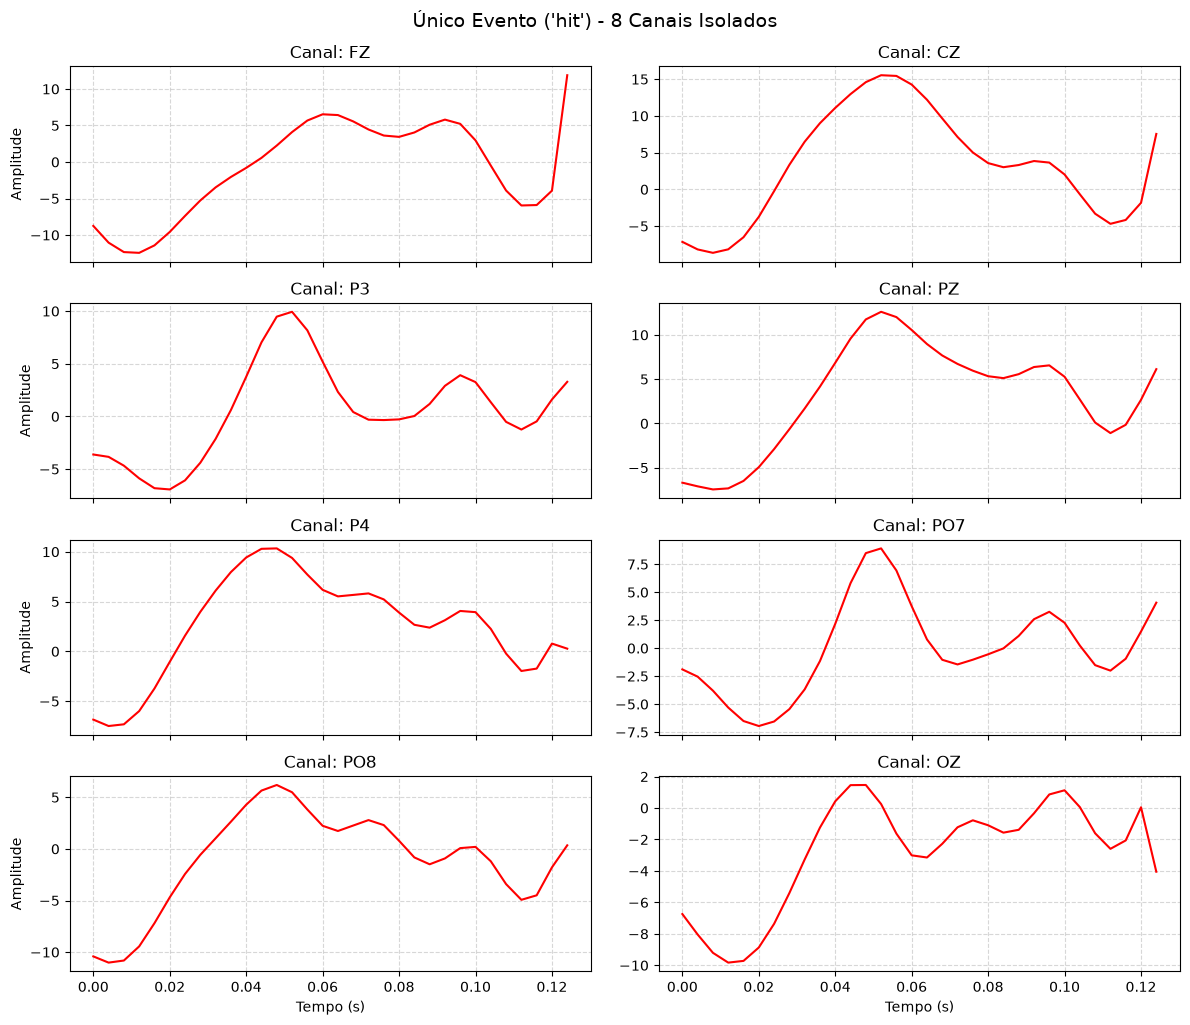

In [20]:
# obtendo 1 'hit' para o plot
single_epoch = epochs["hit"][1]

plots_evoked(single_epoch)

Como os dados obtidos já estão pré-filtrados (1-30 Hz _bandpass_, 50 Hz _notch_), será demonstrado algumas aplicações de filtros somente como exemplos de aplicação.